## 15 Vehicle Type and Trajectory Variations (Flag 15)

### Dataset Overview
A constructed WorldTrace case with 180 trajectories. Route geometries come from observed NYC WorldTrace records and retain map-matched coordinates and OSM way identifiers. User, visit sequence, time, mode, vehicle, and weather context are arranged to realize the stated analysis goal.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze vehicle use and associated trajectory characteristics across the supplied travel history.

Role: Urban mobility analyst


Category: Vehicle size, geometry, speed stability, GPS alignment, and temperature

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; the supporting timestamped trajectory-point table is loaded into `user_df`.

In [ ]:
dataset_path = 'trajectories.csv'
df = pd.read_csv(dataset_path)
df['departure_time'] = pd.to_datetime(df['departure_time'])
df['arrival_time'] = pd.to_datetime(df['arrival_time'])

In [ ]:
user_dataset_path = 'trajectory_points.csv'
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do trajectory distance, route directness, route variety, and turning intensity differ between large and small vehicles?

#### Analysis action

Compare vehicle-level distance and detour ratio, retain distinct source-route counts in the statistics, and derive substantial turns per kilometer from map-matched points.

              trips  distance     ratio  routes  turn_density
vehicle_type                                                 
large           107  6.641888  1.332972       6      1.229056
small            73  3.248589  1.759082      12      2.550258


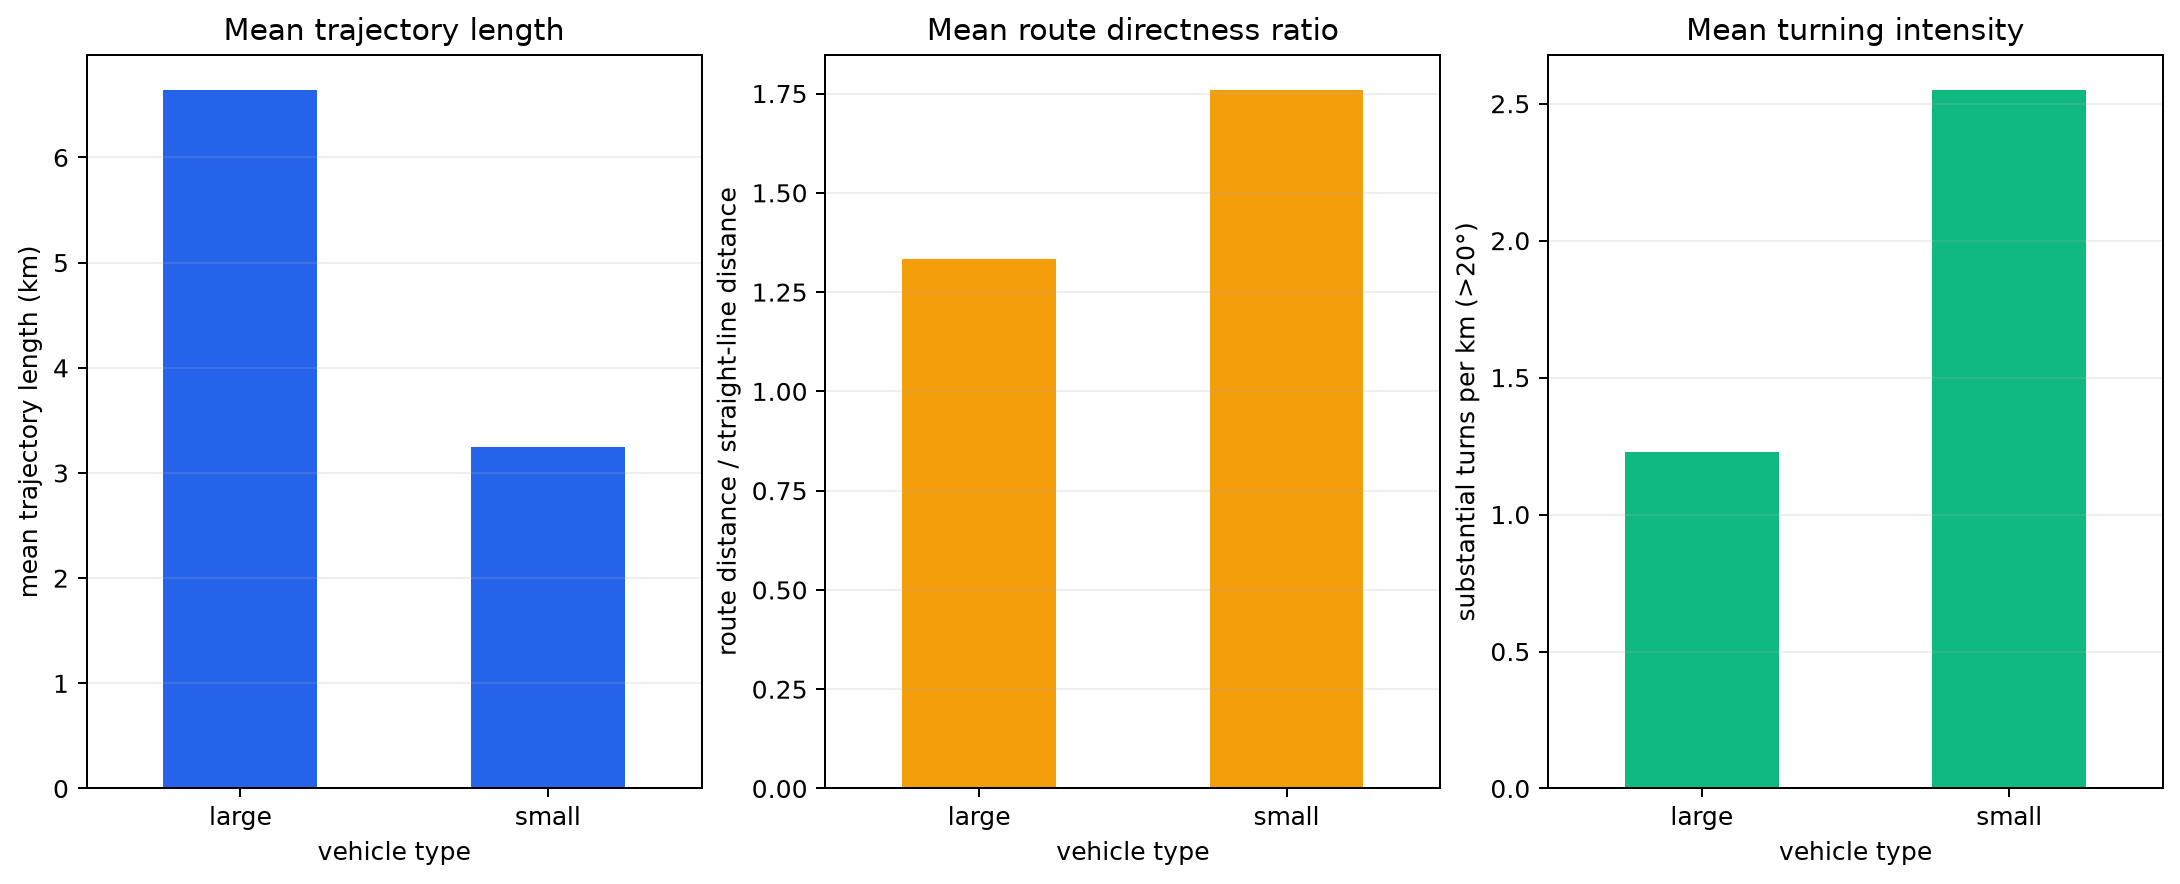

In [1]:
def substantial_turns(q,threshold=20):
    q=q.sort_values('point_index');lat=q.matched_road_latitude.to_numpy();lon=q.matched_road_longitude.to_numpy()
    east=np.diff(lon)*np.cos(np.deg2rad(lat.mean()));north=np.diff(lat);moving=np.hypot(east,north)>1e-10
    headings=np.degrees(np.arctan2(east[moving],north[moving]));changes=np.abs((np.diff(headings)+180)%360-180)
    return int((changes>threshold).sum())
turns=pd.Series({tid:substantial_turns(q) for tid,q in user_df.groupby('trajectory_id')},name='substantial_turn_count')
geometry=df.merge(turns,left_on='trajectory_id',right_index=True)
geometry['turns_per_km']=geometry.substantial_turn_count/geometry.trajectory_distance_km
g=geometry.groupby('vehicle_type').agg(trips=('trajectory_id','size'),distance=('trajectory_distance_km','mean'),ratio=('route_directness_ratio','mean'),routes=('source_trajectory_id','nunique'),turn_density=('turns_per_km','mean'))
print(g)
fig,ax=plt.subplots(1,3,figsize=(12,4.8),constrained_layout=True)
g.distance.plot.bar(ax=ax[0],color='#2563eb');ax[0].set(title='Mean trajectory length',xlabel='vehicle type',ylabel='mean trajectory length (km)')
g.ratio.plot.bar(ax=ax[1],color='#f59e0b');ax[1].set(title='Mean route directness ratio',xlabel='vehicle type',ylabel='route distance / straight-line distance')
g.turn_density.plot.bar(ax=ax[2],color='#10b981');ax[2].set(title='Mean turning intensity',xlabel='vehicle type',ylabel='substantial turns per km (>20°)')
for a in ax: a.tick_params(axis='x',rotation=0);a.grid(axis='y',alpha=.2)
plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex15_insight_1",
  "insight": "Large-vehicle trips tend to follow longer trajectories with higher route directness, while smaller vehicles use a wider variety of shorter and more turning-intensive routes.",
  "plot": {
    "plot_type": "vehicle_distance_directness_and_turn_density_comparison",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Vehicle Type and Trajectory Variations: Insight 1",
    "description": "The panels compare mean trajectory length, route-distance-to-straight-line ratio, and substantial turns per kilometer; distinct source-route counts remain in the printed statistics."
  },
  "question": "How do trajectory distance, route directness, route variety, and turning intensity differ between large and small vehicles?",
  "actionable_insight": "Compare vehicle-level distance and detour ratio, retain distinct source-route counts in the statistics, and derive substantial turns per kilometer from map-matched points.",
  "code": "def substantial_turns(q,threshold=20):\n    q=q.sort_values('point_index');lat=q.matched_road_latitude.to_numpy();lon=q.matched_road_longitude.to_numpy()\n    east=np.diff(lon)*np.cos(np.deg2rad(lat.mean()));north=np.diff(lat);moving=np.hypot(east,north)>1e-10\n    headings=np.degrees(np.arctan2(east[moving],north[moving]));changes=np.abs((np.diff(headings)+180)%360-180)\n    return int((changes>threshold).sum())\nturns=pd.Series({tid:substantial_turns(q) for tid,q in user_df.groupby('trajectory_id')},name='substantial_turn_count')\ngeometry=df.merge(turns,left_on='trajectory_id',right_index=True)\ngeometry['turns_per_km']=geometry.substantial_turn_count/geometry.trajectory_distance_km\ng=geometry.groupby('vehicle_type').agg(trips=('trajectory_id','size'),distance=('trajectory_distance_km','mean'),ratio=('route_directness_ratio','mean'),routes=('source_trajectory_id','nunique'),turn_density=('turns_per_km','mean'))\nprint(g)\nfig,ax=plt.subplots(1,3,figsize=(12,4.8),constrained_layout=True)\ng.distance.plot.bar(ax=ax[0],color='#2563eb');ax[0].set(title='Mean trajectory length',xlabel='vehicle type',ylabel='mean trajectory length (km)')\ng.ratio.plot.bar(ax=ax[1],color='#f59e0b');ax[1].set(title='Mean route directness ratio',xlabel='vehicle type',ylabel='route distance / straight-line distance')\ng.turn_density.plot.bar(ax=ax[2],color='#10b981');ax[2].set(title='Mean turning intensity',xlabel='vehicle type',ylabel='substantial turns per km (>20°)')\nfor a in ax: a.tick_params(axis='x',rotation=0);a.grid(axis='y',alpha=.2)\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vehicle_type",
    "gps_position",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 2**: How does within-trip speed stability differ between large- and small-vehicle trajectories, and is the small-vehicle variation greater on routes with more turns?

#### Analysis action

Compare vehicle-group speed standard deviations, then derive substantial turn counts from map-matched points and relate them to route-level small-vehicle speed variation.

Vehicle-group within-trip speed SD
              mean  median   std   min   max
vehicle_type                                
large          2.5    2.49  0.14  2.28  2.63
small          4.2    4.28  0.38  3.56  4.94
Small-vehicle route evidence
 source_trajectory_id  substantial_turn_count  mean  count
              4391213                       4  3.73      5
              4544034                       5  3.56      8
              5956574                       5  4.08      8
              4637340                       6  3.63      3
              4853709                       8  4.28      5
              4589707                       8  4.35      7
              4838154                       9  4.47      9
              4847288                       9  4.38      8
              5310350                       9  4.46      4
              4447872                      11  4.13      6
              4923945                      11  4.13      4
              4310466                      15  4

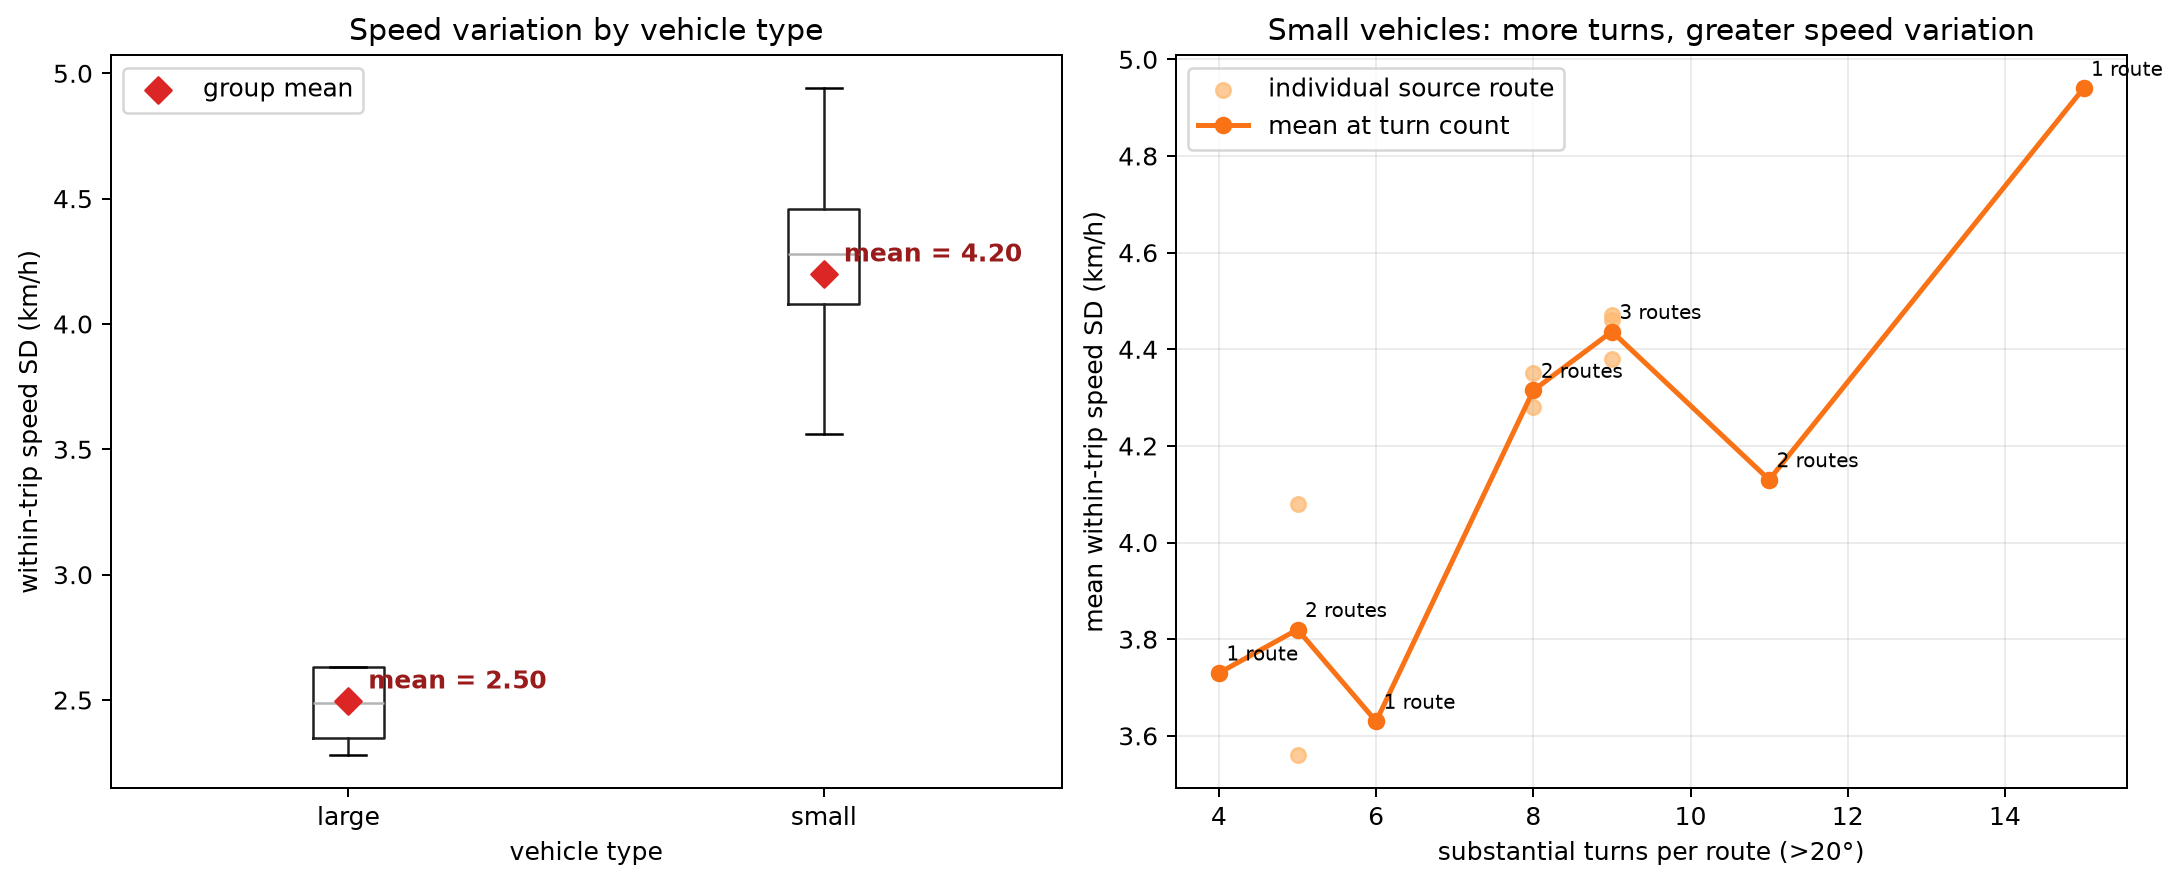

In [2]:
group_stats=df.groupby('vehicle_type').within_trip_speed_sd_kmh.agg(['mean','median','std','min','max'])
print('Vehicle-group within-trip speed SD');print(group_stats.round(2))
def substantial_turns(q,threshold=20):
    q=q.sort_values('point_index');lat=q.matched_road_latitude.to_numpy();lon=q.matched_road_longitude.to_numpy()
    east=np.diff(lon)*np.cos(np.deg2rad(lat.mean()));north=np.diff(lat);moving=np.hypot(east,north)>1e-10
    headings=np.degrees(np.arctan2(east[moving],north[moving]))
    changes=np.abs((np.diff(headings)+180)%360-180)
    return int((changes>threshold).sum())
turns=pd.Series({tid:substantial_turns(q) for tid,q in user_df.groupby('trajectory_id')},name='substantial_turn_count')
evidence=df.merge(turns,left_on='trajectory_id',right_index=True)
small=(evidence[evidence.vehicle_type.eq('small')].groupby(['source_trajectory_id','substantial_turn_count'])
       .within_trip_speed_sd_kmh.agg(['mean','count']).reset_index().sort_values('substantial_turn_count'))
print('Small-vehicle route evidence');print(small.round(2).to_string(index=False))
print('Small-vehicle turn-count correlation',round(small.substantial_turn_count.corr(small['mean']),3))
trend=(small.groupby('substantial_turn_count').agg(mean_speed_sd=('mean','mean'),route_count=('source_trajectory_id','nunique')).reset_index())
fig,ax=plt.subplots(1,2,figsize=(12,4.8),constrained_layout=True)
df.boxplot(column='within_trip_speed_sd_kmh',by='vehicle_type',ax=ax[0],grid=False)
ax[0].set(title='Speed variation by vehicle type',xlabel='vehicle type',ylabel='within-trip speed SD (km/h)')
means=df.groupby('vehicle_type').within_trip_speed_sd_kmh.mean().reindex(['large','small'])
ax[0].scatter([1,2],means,marker='D',s=55,color='#dc2626',zorder=4,label='group mean')
for x,value in enumerate(means,1): ax[0].annotate(f'mean = {value:.2f}',(x,value),xytext=(8,5),textcoords='offset points',color='#991b1b',fontweight='bold')
ax[0].legend(loc='upper left')
ax[1].scatter(small.substantial_turn_count,small['mean'],s=34,color='#fdba74',alpha=.75,label='individual source route')
ax[1].plot(trend.substantial_turn_count,trend.mean_speed_sd,marker='o',linewidth=2,color='#f97316',label='mean at turn count')
for row in trend.itertuples(): ax[1].annotate(f'{row.route_count} route'+('s' if row.route_count>1 else ''),(row.substantial_turn_count,row.mean_speed_sd),xytext=(3,5),textcoords='offset points',fontsize=8)
ax[1].set(title='Small vehicles: more turns, greater speed variation',xlabel='substantial turns per route (>20°)',ylabel='mean within-trip speed SD (km/h)')
ax[1].legend(loc='upper left');ax[1].grid(alpha=.25);plt.suptitle('');plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex15_insight_2",
  "insight": "Large vehicles maintain more stable speeds along their trajectories, whereas smaller vehicles show greater within-trip speed variation, particularly on routes with frequent directional changes.",
  "plot": {
    "plot_type": "vehicle_speed_sd_and_small_vehicle_turn_relationship",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Vehicle Type and Trajectory Variations: Insight 2",
    "description": "The left panel compares within-trip speed standard deviation by vehicle type; the right panel independently traces small-vehicle route-level speed variation against substantial turn count derived from map-matched points."
  },
  "question": "How does within-trip speed stability differ between large- and small-vehicle trajectories, and is the small-vehicle variation greater on routes with more turns?",
  "actionable_insight": "Compare vehicle-group speed standard deviations, then derive substantial turn counts from map-matched points and relate them to route-level small-vehicle speed variation.",
  "code": "group_stats=df.groupby('vehicle_type').within_trip_speed_sd_kmh.agg(['mean','median','std','min','max'])\nprint('Vehicle-group within-trip speed SD');print(group_stats.round(2))\ndef substantial_turns(q,threshold=20):\n    q=q.sort_values('point_index');lat=q.matched_road_latitude.to_numpy();lon=q.matched_road_longitude.to_numpy()\n    east=np.diff(lon)*np.cos(np.deg2rad(lat.mean()));north=np.diff(lat);moving=np.hypot(east,north)>1e-10\n    headings=np.degrees(np.arctan2(east[moving],north[moving]))\n    changes=np.abs((np.diff(headings)+180)%360-180)\n    return int((changes>threshold).sum())\nturns=pd.Series({tid:substantial_turns(q) for tid,q in user_df.groupby('trajectory_id')},name='substantial_turn_count')\nevidence=df.merge(turns,left_on='trajectory_id',right_index=True)\nsmall=(evidence[evidence.vehicle_type.eq('small')].groupby(['source_trajectory_id','substantial_turn_count'])\n       .within_trip_speed_sd_kmh.agg(['mean','count']).reset_index().sort_values('substantial_turn_count'))\nprint('Small-vehicle route evidence');print(small.round(2).to_string(index=False))\nprint('Small-vehicle turn-count correlation',round(small.substantial_turn_count.corr(small['mean']),3))\ntrend=(small.groupby('substantial_turn_count').agg(mean_speed_sd=('mean','mean'),route_count=('source_trajectory_id','nunique')).reset_index())\nfig,ax=plt.subplots(1,2,figsize=(12,4.8),constrained_layout=True)\ndf.boxplot(column='within_trip_speed_sd_kmh',by='vehicle_type',ax=ax[0],grid=False)\nax[0].set(title='Speed variation by vehicle type',xlabel='vehicle type',ylabel='within-trip speed SD (km/h)')\nmeans=df.groupby('vehicle_type').within_trip_speed_sd_kmh.mean().reindex(['large','small'])\nax[0].scatter([1,2],means,marker='D',s=55,color='#dc2626',zorder=4,label='group mean')\nfor x,value in enumerate(means,1): ax[0].annotate(f'mean = {value:.2f}',(x,value),xytext=(8,5),textcoords='offset points',color='#991b1b',fontweight='bold')\nax[0].legend(loc='upper left')\nax[1].scatter(small.substantial_turn_count,small['mean'],s=34,color='#fdba74',alpha=.75,label='individual source route')\nax[1].plot(trend.substantial_turn_count,trend.mean_speed_sd,marker='o',linewidth=2,color='#f97316',label='mean at turn count')\nfor row in trend.itertuples(): ax[1].annotate(f'{row.route_count} route'+('s' if row.route_count>1 else ''),(row.substantial_turn_count,row.mean_speed_sd),xytext=(3,5),textcoords='offset points',fontsize=8)\nax[1].set(title='Small vehicles: more turns, greater speed variation',xlabel='substantial turns per route (>20°)',ylabel='mean within-trip speed SD (km/h)')\nax[1].legend(loc='upper left');ax[1].grid(alpha=.25);plt.suptitle('');plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vehicle_type",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position"
  ]
}

### **Question 3**: How consistently do GPS positions align with matched roads for large and small vehicles?

#### Analysis action

Compare trajectory-level mean GPS-to-road offsets and their upper ranges by vehicle type.

                  mean  median    max
vehicle_type                         
large         3.429813    1.55   6.92
small         6.770411    5.78  12.37


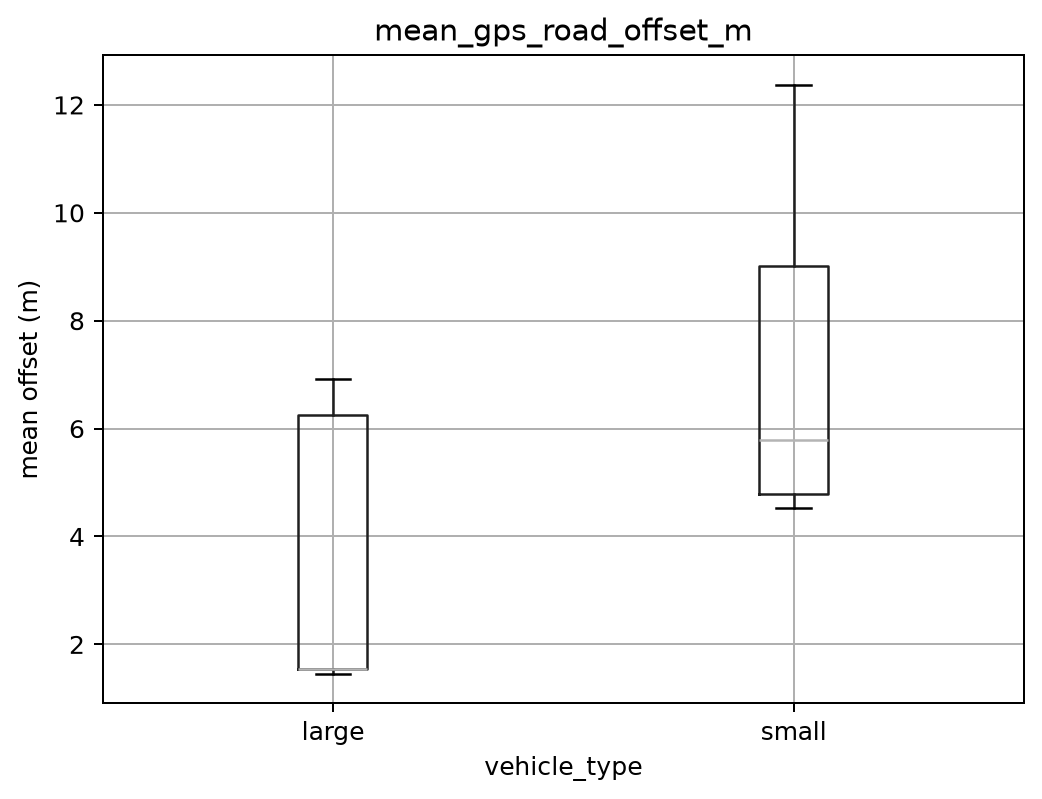

In [3]:
g=df.groupby('vehicle_type').mean_gps_road_offset_m.agg(['mean','median','max']); print(g); df.boxplot(column='mean_gps_road_offset_m',by='vehicle_type'); plt.suptitle(''); plt.ylabel('mean offset (m)'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex15_insight_3",
  "insight": "GPS positions from large-vehicle trips are more consistently aligned with matched roads, while some small-vehicle trajectories contain larger point-to-road offsets in locally complex route segments.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Vehicle Type and Trajectory Variations: Insight 3",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "How consistently do GPS positions align with matched roads for large and small vehicles?",
  "actionable_insight": "Compare trajectory-level mean GPS-to-road offsets and their upper ranges by vehicle type.",
  "code": "g=df.groupby('vehicle_type').mean_gps_road_offset_m.agg(['mean','median','max']); print(g); df.boxplot(column='mean_gps_road_offset_m',by='vehicle_type'); plt.suptitle(''); plt.ylabel('mean offset (m)'); plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vehicle_type",
    "gps_position",
    "matched_road_position",
    "trajectory_id"
  ]
}

### **Question 4**: How does the share of small-vehicle trips vary across the supplied temperature levels?

#### Analysis action

Calculate the small-vehicle share at each temperature and quantify the overall association.

temperature_c
5     33.333333
10    30.000000
15    36.666667
20    40.000000
25    46.666667
30    56.666667
Name: vehicle_type, dtype: float64
correlation 0.931387102341451


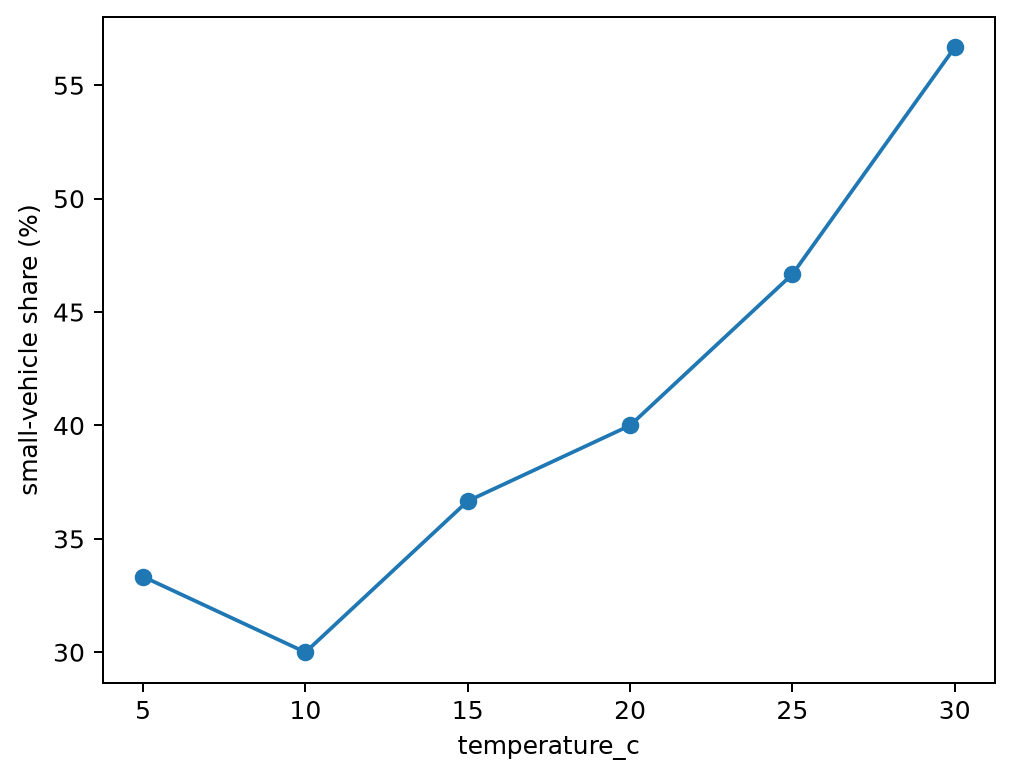

In [4]:
share=df.groupby('temperature_c').vehicle_type.apply(lambda x:(x=='small').mean()*100); print(share); print('correlation',share.index.to_series().corr(share)); share.plot(marker='o'); plt.ylabel('small-vehicle share (%)'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex15_insight_4",
  "insight": "Higher temperature is associated with more frequent use of smaller vehicles, while lower temperature is associated with more frequent use of larger vehicles.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_4.png"
    ],
    "title": "Vehicle Type and Trajectory Variations: Insight 4",
    "description": "The geographic panel uses map-matched WorldTrace route geometry; the question-specific statistical plot summarizes the corresponding pattern."
  },
  "question": "How does the share of small-vehicle trips vary across the supplied temperature levels?",
  "actionable_insight": "Calculate the small-vehicle share at each temperature and quantify the overall association.",
  "code": "share=df.groupby('temperature_c').vehicle_type.apply(lambda x:(x=='small').mean()*100); print(share); print('correlation',share.index.to_series().corr(share)); share.plot(marker='o'); plt.ylabel('small-vehicle share (%)'); plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vehicle_type",
    "temperature",
    "trajectory_id",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 15)

Large-vehicle trips tend to follow longer trajectories with higher route directness, while smaller vehicles use a wider variety of shorter and more turning-intensive routes. Large vehicles maintain more stable speeds along their trajectories, whereas smaller vehicles show greater within-trip speed variation, particularly on routes with frequent directional changes. GPS positions from large-vehicle trips are more consistently aligned with matched roads, while some small-vehicle trajectories contain larger point-to-road offsets in locally complex route segments. Higher temperature is associated with more frequent use of smaller vehicles, while lower temperature is associated with more frequent use of larger vehicles.